# Setup

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn import model_selection
from sklearn.tree import plot_tree
from sklearn.metrics import ConfusionMatrixDisplay

# Setting up palette for plots (ref: https://seaborn.pydata.org/tutorial/color_palettes.html)
palette = sns.color_palette("tab10")
sns.set_palette(palette)

# Defining a function to display percentages labels above barplots (ref: https://www.pythoncharts.com/seaborn/seaborn-bar-plot-value-labels/)
def label_bars(ax): # looping over group of bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%") # print rounded percentage above bar height

### Preliminary Data Structure

In [2]:
# Loading the dataset
data = pd.read_csv("loans.csv",sep = ",")
data.shape 

(5000, 14)

The dataset has 5000 rows and 14 columns, as expected.

In [3]:
# Preview of the data
data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


The dataset was imported correctly and contains no text-valued variables. Let's now take a closer look at the data types.

In [4]:
# Technical summary of the dataset
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


Although all columns are stored as numeric data types (`int64` and `float64`), several variables are binary (`Personal Loan`, `Securities Account`, etc.) or ordinal categorical variables (`Education`) represented numerically.

In [5]:
# Checking if there is any missing values
data.isna().sum()

ID                    0
Age                   0
Experience            0
Income                0
ZIP Code              0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal Loan         0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

The check shows that there are no missing values in any of the variables, so no missing-value treatment or in-depth data cleaning is required for the following analysis.

In [6]:
# Checking if the identifier is unique
data["ID"].nunique()

5000

The dataset contains 5,000 observations and 5,000 unique IDs, indicating that each ID corresponds to a single observation. We therefore do not need to aggregate observations. Let's also check for duplicated rows.

In [7]:
# Removing any duplicated rows
data = data.drop_duplicates()
data.shape 

(5000, 14)

No duplicated rows were found, so no deduplication is necessary. The preliminary checks show that the dataset is ready for exploratory analysis, although some variables may need to be recasted.

### Exploratory Data Analysis

In [8]:
# Descriptive statistics
data.describe().T
# print(data.describe().T.to_markdown()) # Descriptive statistics table for the report

,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


The dataset does not show any obvious extreme values based on the descriptive statistics. However, negative values are found in the `Experience` variable, so there observations need to be further investigated.

In [9]:
# Investigating negative experience observations
data_negative_exp = data[data["Experience"] < 0]
data_negative_exp.describe().T
# print(data_negative_exp.describe().T.to_markdown()) # Descriptive statistics table for the report

,count,mean,std,min,25%,50%,75%,max
ID,52.0,2427.346154,1478.834118,90.0,767.25,2783.5,3669.500,4958.0
Age,52.0,24.519231,1.475159,23.0,24.00,24.0,25.000,29.0
Experience,52.0,-1.442308,0.639039,-3.0,-2.00,-1.0,-1.000,-1.0
Income,52.0,69.942308,37.955295,12.0,40.75,65.5,86.750,150.0
ZIP Code,52.0,93240.961538,1611.654806,90065.0,92167.75,93060.0,94720.000,95842.0
Family,52.0,2.865385,0.970725,1.0,2.00,3.0,4.000,4.0
CCAvg,52.0,2.129423,1.750562,0.2,1.00,1.8,2.325,7.2
Education,52.0,2.076923,0.836570,1.0,1.00,2.0,3.000,3.0
Mortgage,52.0,43.596154,90.027068,0.0,0.00,0.0,0.000,314.0
Personal Loan,52.0,0.000000,0.000000,0.0,0.00,0.0,0.000,0.0


There are 52 observations with negative experience, representing 1.04% of the entire dataset. These observations involve relatively young customers, aged between 23 and 29, whom generally have lower incomes than the full sample. This may indicate data-entry errors or a deliberate coding convention.

### Recasting and cleaning variables

In [10]:
data[["Age", "Experience"]].corr()
data[["Experience", "Personal Loan"]].corr()

,Experience,Personal Loan
Experience,1.000000,-0.007413
Personal Loan,-0.007413,1.000000


`Age` and `Experience` are almost perfectly correlated (correlation of 0.99), such that experience is almost a deterministic function of Age. Moreover, it has little to no correlation with the target variable `Personal Loan`. Since it carries no extra information and seemingly suffers from badly encoded values (52 negative values as spotted above), we decide to ignore `Experience` in the following analysis instead of trying to fix it.

In [11]:
# Renaming variables for clarity
data = data.rename(columns={
    "CreditCard": "Credit Card",
    "Online": "Online Facilities",
    "CD Account": "Deposit Account",
})

### Question 1: What is the conversion rate (percentage of clients that contracted a personal loan) of the marketing campaign?

In [12]:
# Normalized Value Counts of the Loan Variable 
print(data["Personal Loan"].value_counts())
print(data["Personal Loan"].value_counts(normalize=True) * 100)

Personal Loan
0    4520
1     480
Name: count, dtype: int64
Personal Loan
0    90.4
1     9.6
Name: proportion, dtype: float64


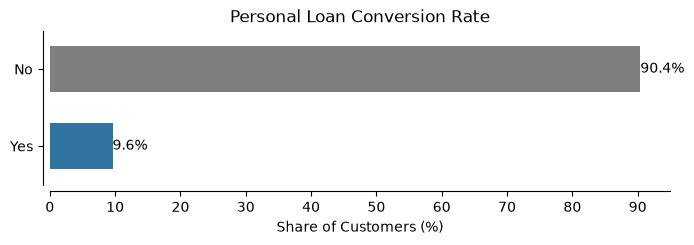

In [13]:
fig, ax = plt.subplots(figsize=(8, 2))

sns.countplot(
    data=data,
    y="Personal Loan",
    hue="Personal Loan",
    palette={0: palette[7], 1: palette[0]},
    order=[0, 1], 
    stat="percent",
    width=0.6,
    legend=False,
    ax=ax,
)
label_bars(ax) # displaying percentages labels above bars

ax.set(
    title="Personal Loan Conversion Rate",
    xlabel="Share of Customers (%)",
    ylabel=None,
    xticks=np.arange(0, 100, 10),
    yticks=[0, 1],
    yticklabels=["No", "Yes"],
)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q1.pdf", bbox_inches="tight") # tight border margins for the report
plt.show()

Given that each identifier is unique, only 480 out of 5000 clients contracted a personal loan, corresponding to a campaign conversion rate of 9.6%. This class imbalance is pretty important for the rest of the analysis, since it means that a naive model always predicting "No" will achieve an accuracy of 90.4%. Therefore, accuracy might be a misleading metric when evaluating our classifiers.

### Question 2: How are the different variables (age, income, education, etc.) distributed in the dataset?


#### Distribution of Customers Profile (Age, Education, Family Size)

In [14]:
print(data[["Age", "Family"]].describe().T) # Summary statistics 

print(data["Family"].value_counts()) # Counts per Education level
print(data["Family"].value_counts(normalize=True) * 100) # Share of customers per Education level

print(data["Education"].value_counts()) # Counts per Education level
print(data["Education"].value_counts(normalize=True) * 100) # Share of customers per Education level

         count     mean        std   min   25%   50%   75%   max
Age     5000.0  45.3384  11.463166  23.0  35.0  45.0  55.0  67.0
Family  5000.0   2.3964   1.147663   1.0   1.0   2.0   3.0   4.0
Family
1    1472
2    1296
4    1222
3    1010
Name: count, dtype: int64
Family
1    29.44
2    25.92
4    24.44
3    20.20
Name: proportion, dtype: float64
Education
1    2096
3    1501
2    1403
Name: count, dtype: int64
Education
1    41.92
3    30.02
2    28.06
Name: proportion, dtype: float64


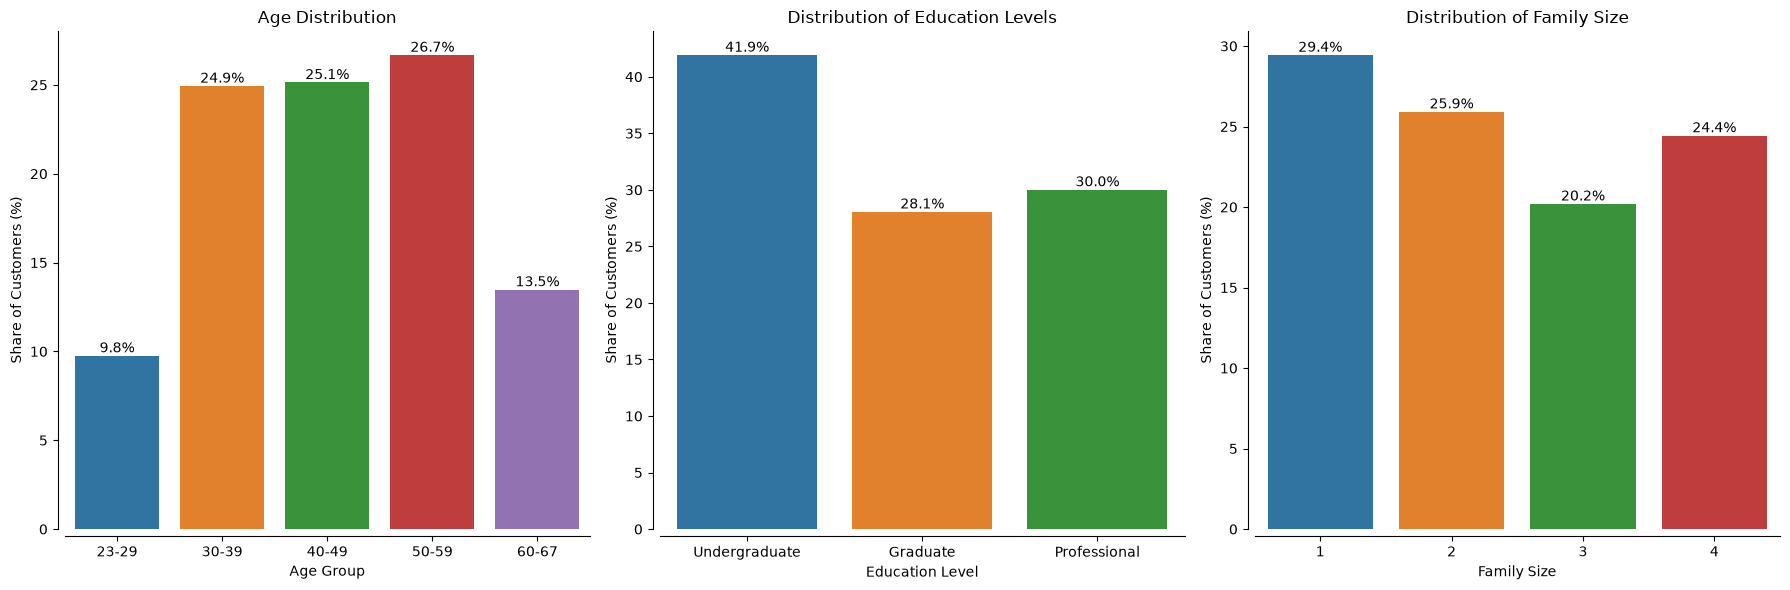

In [15]:
# Decadal age categories for simpler visualization
age_groups = pd.cut(
    data["Age"],
    bins=[20, 29, 39, 49, 59, 70],
    labels=["23-29", "30-39", "40-49", "50-59", "60-67"],
)

# Plot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Left plot: Age Distribution
sns.countplot(
    x=age_groups,
    hue=age_groups,
    stat="percent", # displaying percentages instead of counts
    dodge=False, # preserve bars width and centering when using hue
    legend=False,
    ax=axes[0]
)
label_bars(axes[0])  # displaying percentages labels above bars
axes[0].set(
    title="Age Distribution",
    xlabel="Age Group",
    ylabel="Share of Customers (%)",
)

# 2. Middle plot: Education Levels
sns.countplot(
    data=data,
    x="Education",
    hue="Education",
    palette=palette[:3], # differentiate color for each bar
    order=[1, 2, 3],
    stat="percent", # displaying percentages instead of counts
    legend=False,
    ax=axes[1],
)
label_bars(axes[1]) # displaying percentages labels above bars
axes[1].set(
    title="Distribution of Education Levels",
    xlabel="Education Level",
    ylabel="Share of Customers (%)",
    xticks=[0, 1, 2],
    xticklabels=["Undergraduate", "Graduate", "Professional"], # replace codes with labels for clarity
)

# 2. Right plot: Family Size
sns.countplot(
    data=data,
    x="Family",
    hue="Family",
    palette=palette[:4], # differentiate color for each bar
    stat="percent", # displaying percentages instead of counts
    legend=False,
    ax=axes[2],
)
label_bars(axes[2])  # displaying percentages labels above bars
axes[2].set(
    title="Distribution of Family Size",
    xlabel="Family Size",
    ylabel="Share of Customers (%)",
)

sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q2a.pdf", bbox_inches="tight")
plt.show()

The customer base is heavily concentrated in middle-aged brackets: clients aged 30-59 make up 76.7% of the dataset, spread almost evenly across age groups. Undergraduate form the largest group, as well as one person households. 

#### Distribution of Financial Variables (Income, Credit Card Spendings, Mortgage)

In [16]:
print(data[["Income", "CCAvg", "Mortgage"]].describe().T) # Summary statistics
print((data[["Income", "CCAvg", "Mortgage"]] == 0).mean() * 100) # Share of clients with 0 value
print(data[data["Mortgage"] > 0]["Mortgage"].min()) # Minimum non zero mortgage value

           count       mean         std  min   25%   50%    75%    max
Income    5000.0  73.774200   46.033729  8.0  39.0  64.0   98.0  224.0
CCAvg     5000.0   1.937938    1.747659  0.0   0.7   1.5    2.5   10.0
Mortgage  5000.0  56.498800  101.713802  0.0   0.0   0.0  101.0  635.0
Income       0.00
CCAvg        2.12
Mortgage    69.24
dtype: float64
75


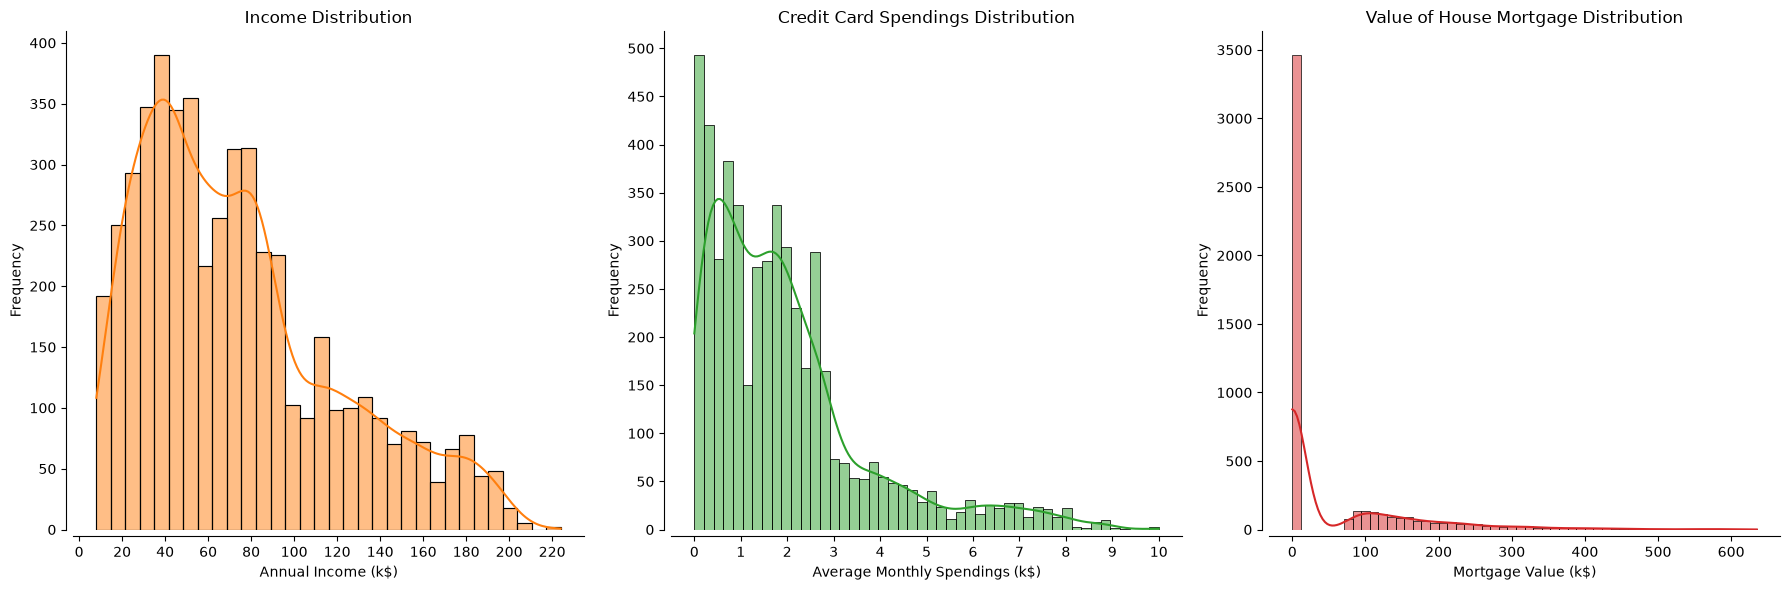

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))

# 1. Left plot: Income Distribution
sns.histplot(
    data["Income"],
    kde=True, # histogram + density curve
    color=palette[1],
    ax=axes[0]
)
axes[0].set(
    title="Income Distribution",
    xlabel="Annual Income (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, 224, 20), 
)

# 2. Middle plot: Average monthly spendings on credit card (in $k)
sns.histplot(
    data["CCAvg"],
    kde=True, # histogram + density curve
    color=palette[2],
    ax=axes[1]
)
axes[1].set(
    title="Credit Card Spendings Distribution",
    xlabel="Average Monthly Spendings (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, 11), # adding 1 to the max (11) for the max value (10) to be displayed
    yticks=np.arange(0, 501, 50)
)

# 3. Right plot: Value of house mortgage (in $k)
sns.histplot(
    data["Mortgage"],
    kde=True, # histogram + density curve
    color=palette[3],
    ax=axes[2]
)
axes[2].set(
    title="Value of House Mortgage Distribution",
    xlabel="Mortgage Value (k$)",
    ylabel="Frequency",
    xticks=np.arange(0, 635, 100)
)

sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q2b.pdf", bbox_inches="tight")
plt.show()

69,24% customers have no mortgage at all, while only 2,12% have zero monthly credit card spending. The three variables are right skewed. Among mortgage holders, minimum mortgage value is 75 k$ (minimum loan floor ?)

#### Distribution of Banking Products (Loan, Securities Account, CD Account, Online and Credit Card)

To facilitate the comparison of all five binary variables on a single plot, we first calculate the percentage distribution for each banking products before reshaping the data into long-format (required to display multiple variables on the same axes). 

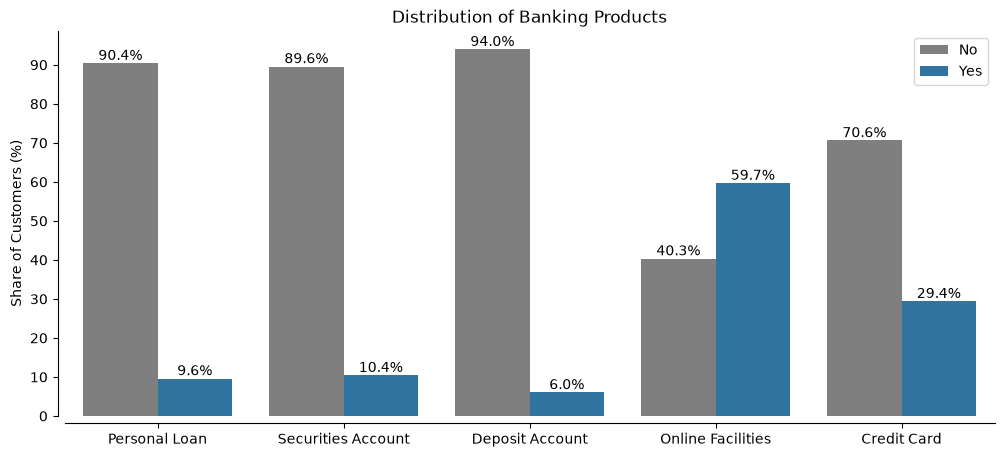

In [18]:
# Defining binary variables
binary_variables = ["Personal Loan", "Securities Account", "Deposit Account", "Online Facilities", "Credit Card"]

# Compute "Yes" and "No" percentage shares for each variable
yes_pct = data[binary_variables].mean() * 100 # Yes share 
binary_data = pd.DataFrame({"No": 100 - yes_pct, "Yes": yes_pct}) 

# Reshaping from wide to long to plot all variables side by side
binary_data = binary_data.melt( 
    ignore_index=False, # keeping variable names in the index
    var_name="Response", # yes or no labels
    value_name="Percent" # percentage values
)

# Plot
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(
    data=binary_data,
    x=binary_data.index, # variable names from the index
    y="Percent",
    hue="Response",
    palette={"No": palette[7], "Yes": palette[0]},
    ax=ax)
label_bars(ax)  # displaying percentages labels above bars

ax.set(
    title="Distribution of Banking Products",
    xlabel=None,
    ylabel="Share of Customers (%)",
    yticks=np.arange(0, 100, 10)
)
ax.legend(title=None)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q2c.pdf", bbox_inches="tight")
plt.show()

Most banking products held by only a small fraction of customers, roughly 90% or more do not hold Personal Loans, Securities Accounts or Deposit Account. Credit Cards are more common with an adoption rate of 29.4%, while Online Banking is by far the most widely used service with 59.7% of customers enrolled.

### Question 3: How do the different variables interact with each other?


#### Correlation Matrix

We first compute a correlation matrix to inspect how customers features potentially interact together. Since the dataset mixes binary, ordinal and skewed continuous variables, we use Spearman correlation.

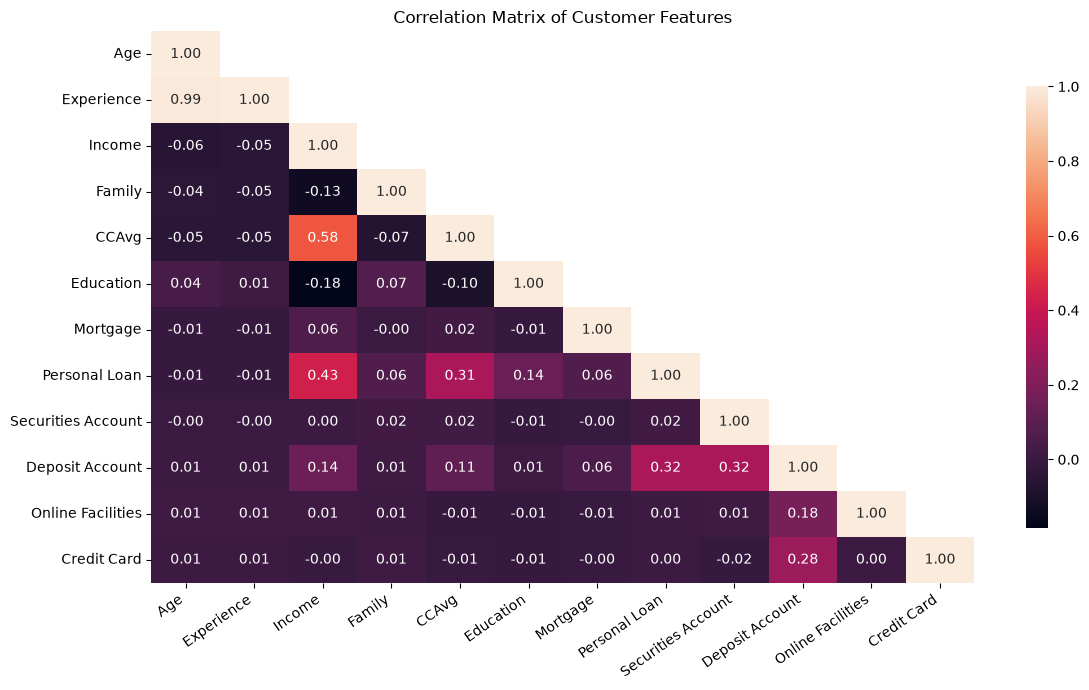

In [19]:
# Exclude non-informative identifier variables
df_corr = data.drop(columns=["ID", "ZIP Code"]).copy()
corr = df_corr.corr(method="spearman") # rank correlation

# Hiding the upper triangle for clarity
mask = np.triu(np.ones_like(corr, dtype=bool), k=1) # k=1 keeps the diagonal

# Plot
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    corr, 
    mask=mask,
    annot= True, # display coefficients inside each matrix cell
    fmt=".2f", # rounding coefficients
    cbar_kws={"shrink": 0.8}, # shrinking the gradient color bar
    ax=ax
)
ax.set(title="Correlation Matrix of Customer Features")
plt.xticks(rotation=35, ha="right") # rotating x-axis labels and aligning right
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q3a.pdf", bbox_inches="tight")
plt.show()

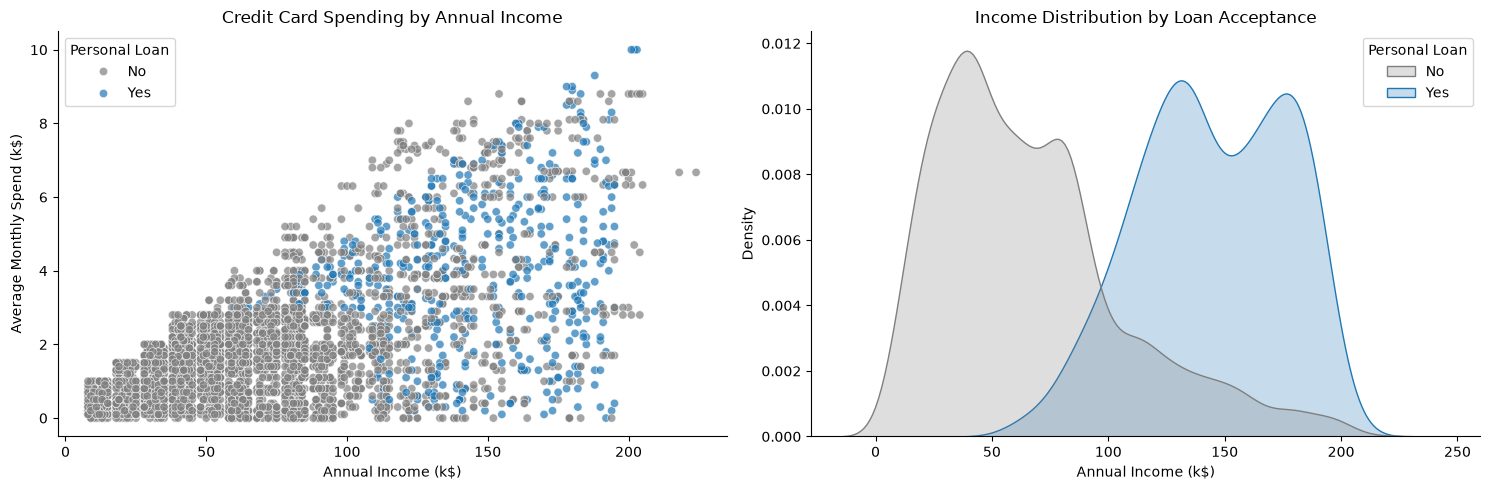

In [20]:
# Dataplot (for the legend label)
data_plot = data.copy()
data_plot["Personal Loan"] = data_plot["Personal Loan"].map({0: "No", 1: "Yes"})

# Plot (1x2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left plot: Credit Card spending x Income
sns.scatterplot(
    data=data_plot,
    x="Income",
    y="CCAvg",
    hue="Personal Loan",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    alpha=0.7,
    ax=axes[0]
)
axes[0].set(
    title="Credit Card Spending by Annual Income",
    xlabel="Annual Income (k$)",
    ylabel="Average Monthly Spend (k$)"
)

# Right Plot: Density of Income by Loan status
sns.kdeplot(
    data=data_plot,
    x="Income",
    hue="Personal Loan",
    fill=True,
    palette={"No": palette[7], "Yes": palette[0]},
    common_norm=False, # normalize each group density for clarity
    ax=axes[1]
)
axes[1].set(
    title="Income Distribution by Loan Acceptance",
    xlabel="Annual Income (k$)",
    ylabel="Density"
)

sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q3b.pdf", bbox_inches="tight")
plt.show()

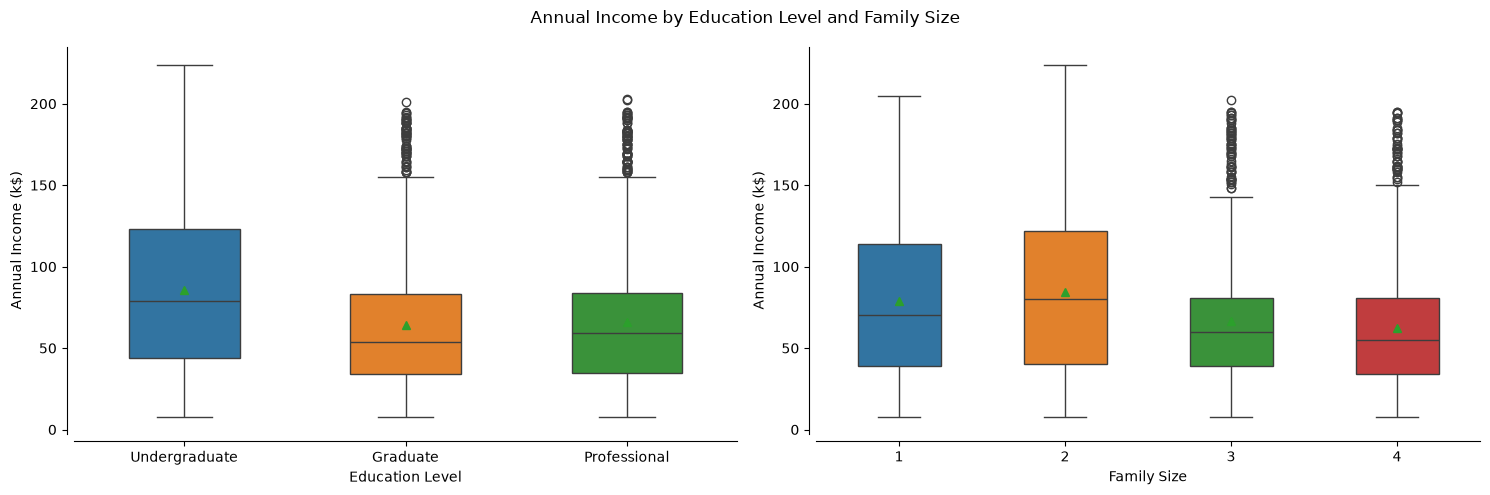

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=data,
    x="Education",
    y="Income",
    hue="Education",
    palette=palette[:3],
    order=[1, 2, 3],
    width=0.5,
    showmeans=True, # display the mean
    legend=False, # deactivate legend redundant with x-axis labels
    ax=axes[0],
)
axes[0].set(
    xlabel="Education Level",
    ylabel="Annual Income (k$)",
    xticks=[0, 1, 2], 
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

sns.boxplot(
    data=data,
    x="Family",
    y="Income",
    hue="Family",
    palette=palette[:4],
    width=0.5,
    showmeans=True, # display the mean
    legend=False, # deactivate legend redundant with x-axis labels
    ax=axes[1]
)
axes[1].set(
    xlabel="Family Size",
    ylabel="Annual Income (k$)"
)

plt.suptitle("Annual Income by Education Level and Family Size") # Common title for the subplot
sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q3c.pdf", bbox_inches="tight")
plt.show()

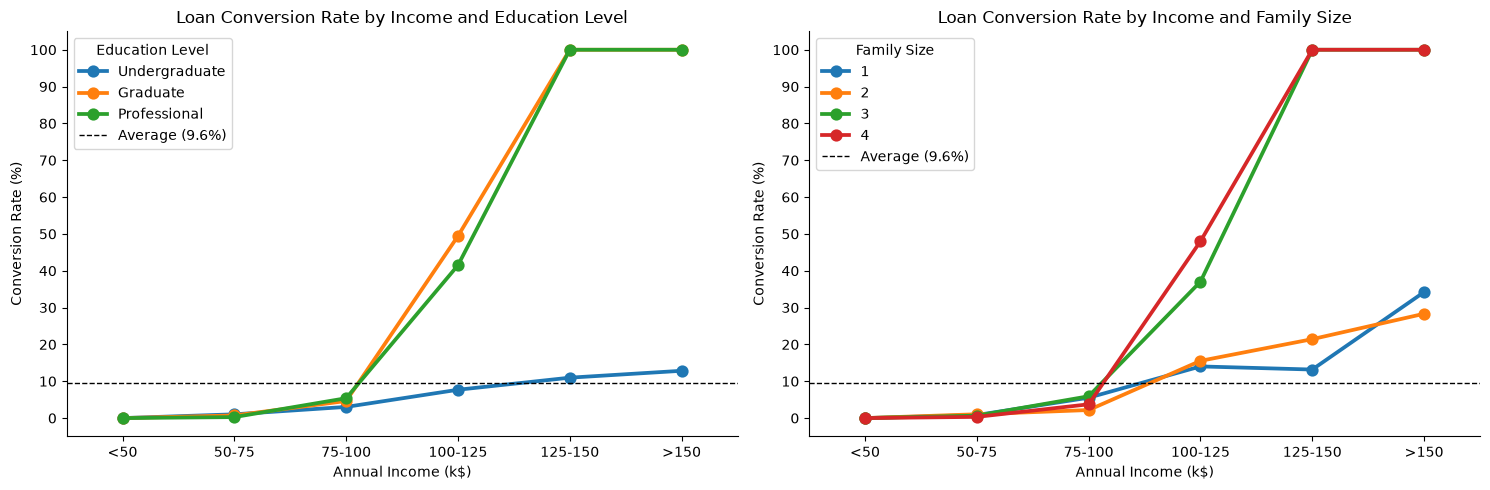

In [22]:
# Creating group categories and readable label for plotting
data_plot = data.copy()
data_plot["Income Band"] = pd.cut(
    data_plot["Income"],
    bins=[0, 50, 75, 100, 125, 150, 225],
    labels=["<50", "50-75", "75-100", "100-125", "125-150", ">150"],
)
data_plot["Education"] = data_plot["Education"].map({
    1: "Undergraduate",
    2: "Graduate",
    3: "Professional",
})

average_rate = data["Personal Loan"].mean() * 100 # Defining the average rate of conversion (9,6%)

# Plot (1x2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

## Plot 1: Conversion Rate by Income and Education Level
sns.pointplot(
    data=data_plot,
    x="Income Band",
    y=data_plot["Personal Loan"] * 100, # average loan conversion rate within group
    hue="Education",
    hue_order=["Undergraduate", "Graduate", "Professional"],
    palette=palette[:3], # one color for each line/dot
    errorbar=None, # deactivating error bars around the dots
    ax=axes[0],
)
axes[0].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Average (9.6%)",
)
axes[0].set(
    title="Loan Conversion Rate by Income and Education Level",
    xlabel="Annual Income (k$)",
    ylabel="Conversion Rate (%)",
    yticks=np.arange(0, 101, 10), # more precise ticks 
)
axes[0].legend(title="Education Level")

## Plot 2: Conversion Rate by Income and Family Size
sns.pointplot(
    data=data_plot,
    x="Income Band",
    y=data_plot["Personal Loan"] * 100, # average loan conversion rate within group
    hue="Family",
    palette=palette[:4], # one color for each line/dot
    errorbar=None, # deactivating error bars around the dots
    ax=axes[1],
)
axes[1].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Average (9.6%)",
)
axes[1].set(
    title="Loan Conversion Rate by Income and Family Size",
    xlabel="Annual Income (k$)",
    ylabel="Conversion Rate (%)",
    yticks=np.arange(0, 101, 10) # more precise ticks 
)
axes[1].legend(title="Family Size")

sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q3d.pdf", bbox_inches="tight")
plt.show()

In [23]:
# Three-way interaction between high-income  x education x family size
high_inc = data_plot[data_plot["Income"] > 125]
print(high_inc.groupby(["Education", "Family"])["Personal Loan"].mean() * 100)
print(high_inc.groupby(["Education", "Family"])["Personal Loan"].count())

Education      Family
Graduate       1         100.0
               2         100.0
               3         100.0
               4         100.0
Professional   1         100.0
               2         100.0
               3         100.0
               4         100.0
Undergraduate  1           0.0
               2           0.0
               3         100.0
               4         100.0
Name: Personal Loan, dtype: float64
Education      Family
Graduate       1          25
               2          38
               3          34
               4          28
Professional   1          44
               2          38
               3          36
               4          34
Undergraduate  1         212
               2         223
               3          32
               4          27
Name: Personal Loan, dtype: int64


Clear effect above 100k$ to investigate

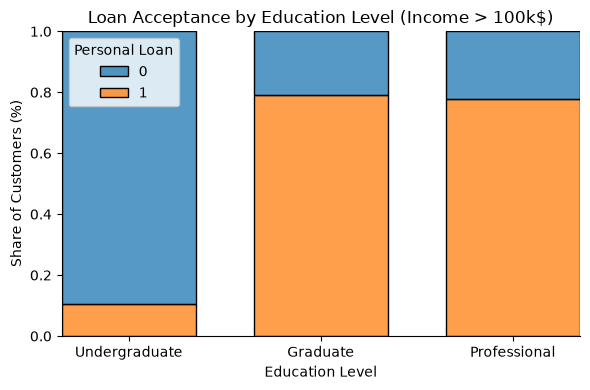

In [24]:
# Filtering customers with income above 100k$
high_income_data = data[data["Income"] > 100].copy()

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(
    data=high_income_data,
    x="Education",
    hue="Personal Loan",
    hue_order=[0, 1],
    multiple="fill", # stacked bars
    discrete=True, # centering bars on ticks
    shrink=0.7, # reduce bars width
    ax=ax,
)

ax.set(
    title="Loan Acceptance by Education Level (Income > 100k$)",
    xlabel="Education Level",
    ylabel="Share of Customers (%)",
    xticks=[1, 2, 3],
    xticklabels=["Undergraduate", "Graduate", "Professional"]
)

sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q3e.pdf", bbox_inches="tight")
plt.show()

### Question 4: Are age, income, education, etc. distributed similarly for customers who have security accounts and those who don't?

We first proceed by computing the Mann-Whitney U test for continuous variable to test whether the customers with or without security accounts have the same underlying distribution or not. Second we compute the chi-squared test of independence for categorical variables. 

In [25]:
# Filtering customers with or without Securities Account
yes = data[data["Securities Account"] == 1] 
no = data[data["Securities Account"] == 0]

# Mann-Whitney U test (for continuous variables)
print("Age:", stats.mannwhitneyu(yes["Age"], no["Age"]))
print("Income:", stats.mannwhitneyu(yes["Income"], no["Income"]))
print("CCAvg:", stats.mannwhitneyu(yes["CCAvg"], no["CCAvg"]))
print("Mortgage:", stats.mannwhitneyu(yes["Mortgage"], no["Mortgage"]))

# chi-squared test (for categorical variables)
print("Education:", stats.chi2_contingency(pd.crosstab(data["Education"], data["Securities Account"])))
print("Family:", stats.chi2_contingency(pd.crosstab(data["Family"], data["Securities Account"])))
print("Online Facilities:", stats.chi2_contingency(pd.crosstab(data["Online Facilities"], data["Securities Account"])))
print("Credit Card:", stats.chi2_contingency(pd.crosstab(data["Credit Card"], data["Securities Account"])))
print("Personal Loan:", stats.chi2_contingency(pd.crosstab(data["Personal Loan"], data["Securities Account"])))

Age: MannwhitneyuResult(statistic=np.float64(1168227.0), pvalue=np.float64(0.9864349068389239))
Income: MannwhitneyuResult(statistic=np.float64(1177543.5), pvalue=np.float64(0.7783411374480849))
CCAvg: MannwhitneyuResult(statistic=np.float64(1210692.0), pvalue=np.float64(0.17892383853634275))
Mortgage: MannwhitneyuResult(statistic=np.float64(1161748.5), pvalue=np.float64(0.7835089335493282))
Education: Chi2ContingencyResult(statistic=np.float64(0.7714682435445044), pvalue=np.float64(0.6799512858920017), dof=2, expected_freq=array([[1877.1776,  218.8224],
       [1256.5268,  146.4732],
       [1344.2956,  156.7044]]))
Family: Chi2ContingencyResult(statistic=np.float64(2.13675190436645), pvalue=np.float64(0.5445134585195501), dof=3, expected_freq=array([[1318.3232,  153.6768],
       [1160.6976,  135.3024],
       [ 904.556 ,  105.444 ],
       [1094.4232,  127.5768]]))
Online Facilities: Chi2ContingencyResult(statistic=np.float64(0.7153024169236211), pvalue=np.float64(0.3976891379898248

In [26]:
# Distribution of continuous variables by securities account status
print(data.groupby("Securities Account")[["Age", "Income", "CCAvg", "Mortgage"]].describe().T)

Securities Account            0           1
Age      count      4478.000000  522.000000
         mean         45.340107   45.323755
         std          11.468762   11.425994
         min          23.000000   23.000000
         25%          35.000000   36.000000
         50%          45.000000   45.000000
         75%          55.000000   55.000000
         max          67.000000   67.000000
Income   count      4478.000000  522.000000
         mean         73.815319   73.421456
         std          46.214711   44.492344
         min           8.000000    8.000000
         25%          39.000000   40.000000
         50%          64.000000   65.000000
         75%          98.000000   98.000000
         max         224.000000  205.000000
CCAvg    count      4478.000000  522.000000
         mean          1.928937    2.015153
         std           1.747880    1.745528
         min           0.000000    0.000000
         25%           0.700000    0.700000
         50%           1.500000 

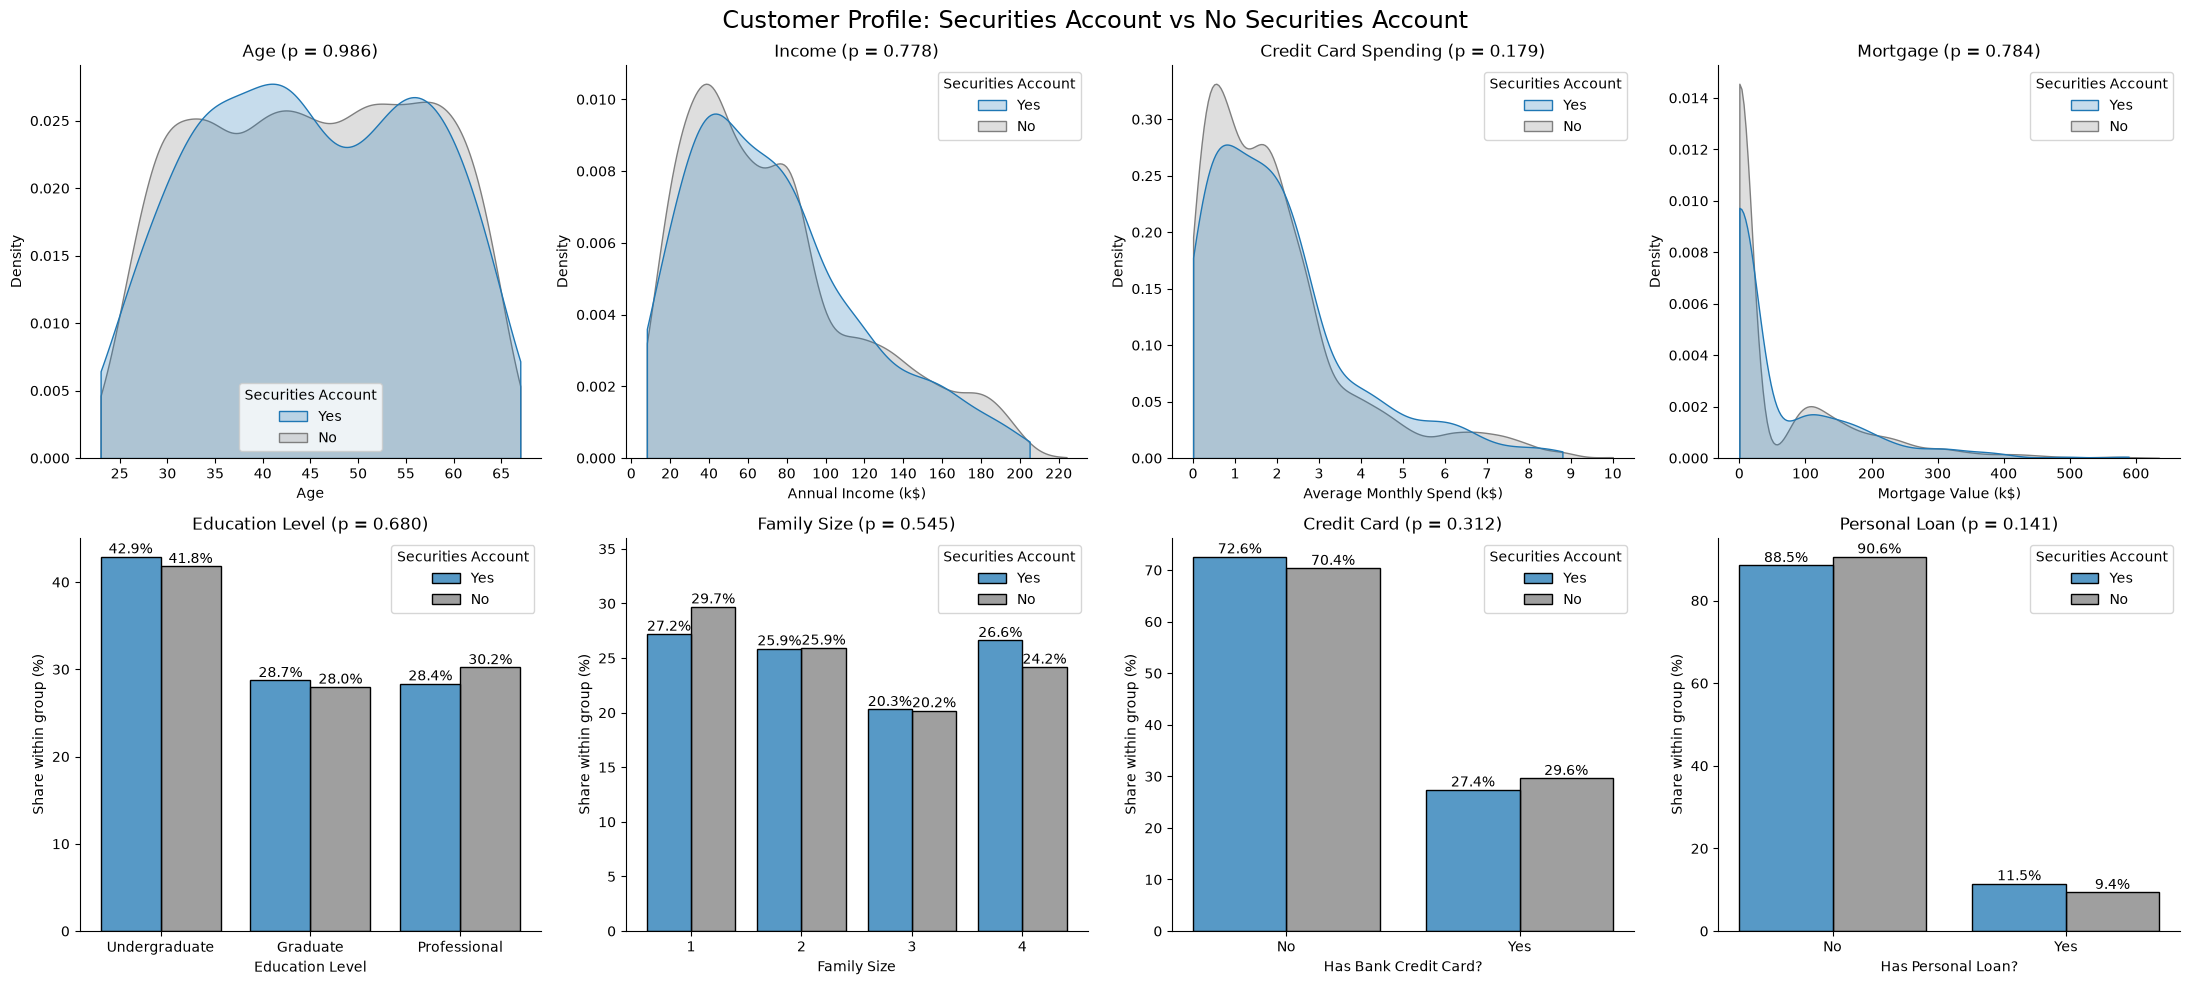

In [27]:
# Dataplot and rename binary variables modalities (Yes/No instead of 1/0)
data_plot = data.copy()
data_plot["Securities Account"] = data_plot["Securities Account"].map({0:"No", 1:"Yes"})
data_plot["Online Facilities"] = data_plot["Online Facilities"].map({0:"No", 1:"Yes"})
data_plot["Credit Card"] = data_plot["Credit Card"].map({0:"No", 1:"Yes"})
data_plot["Deposit Account"] = data_plot["Deposit Account"].map({0:"No", 1:"Yes"})
data_plot["Personal Loan"] = data_plot["Personal Loan"].map({0:"No", 1:"Yes"})

# Panel plot (2x4)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

# Row 1: Continuous variables
## Plot 1: Age
sns.kdeplot(
    data=data_plot,
    x="Age",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True, 
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[0]
)
axes[0].set(
    title="Age (p = 0.986)",
    xlabel="Age",
    ylabel="Density",
    xticks=np.arange(25, 66, 5)
)

## Plot 2: Income
sns.kdeplot(
    data=data_plot,
    x="Income",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[1]
)
axes[1].set(
    title="Income (p = 0.778)",
    xlabel="Annual Income (k$)",
    ylabel="Density",
    xticks=np.arange(0, 240, 20)
)

## Plot 3: Average Credit Card Spending
sns.kdeplot(
    data=data_plot,
    x="CCAvg",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[2],
)
axes[2].set(
    title='Credit Card Spending (p = 0.179)',
    xlabel='Average Monthly Spend (k$)',
    ylabel='Density',
    xticks=np.arange(0, 11),
)

## Plot 4: House Mortgage Value
sns.kdeplot(
    data=data_plot,
    x="Mortgage",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[3],
)
axes[3].set(
    title="Mortgage (p = 0.784)",
    xlabel="Mortgage Value (k$)",
    ylabel="Density",
    xticks=np.arange(0, 620, 100)
)

# Row 2: Categorical variables
## Plot 5: Education
sns.histplot(
    data=data_plot,
    x="Education",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[4],
)
label_bars(axes[4])
axes[4].set(
    title="Education Level (p = 0.680)",
    xlabel="Education Level",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

## Plot 6: Family Size
sns.histplot(
    data=data_plot,
    x="Family",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[5],
)
label_bars(axes[5])
axes[5].set(
    title="Family Size (p = 0.545)",
    xlabel="Family Size",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3, 4],
    ylim=(0, 36)
)

## Plot 7: Credit Card
sns.histplot(
    data=data_plot,
    x="Credit Card",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[6]
)
label_bars(axes[6])
axes[6].set(
    title="Credit Card (p = 0.312)",
    xlabel="Has Bank Credit Card?", 
    ylabel="Share within group (%)"
)

## Plot 8: Personal Loan
sns.histplot(
    data=data_plot,
    x="Personal Loan",
    hue="Securities Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[7]
)
label_bars(axes[7])
axes[7].set(
    title="Personal Loan (p = 0.141)",
    xlabel="Has Personal Loan?", 
    ylabel="Share within group (%)"
)

plt.suptitle("Customer Profile: Securities Account vs No Securities Account", fontsize=17)
sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q4.pdf", bbox_inches="tight")
plt.show()

No test is significant at the 95% confidence level, meaning that customers with a securities account and those without do not systematically differ in any of these dimensions. This can be seen visually by the strong overlap in the distributions between the two groups for every variables  

### Question 5: Are age, income, education, etc. distributed similarly for customers who have CD accounts and those who don't?

We proceed similarly for the comparison of customers with and without a deposit account. 

In [28]:
yes = data[data["Deposit Account"] == 1] 
no = data[data["Deposit Account"] == 0]

# Continuous variables: Mann-Whitney U test
print("Age:", stats.mannwhitneyu(yes["Age"], no["Age"]))
print("Income:", stats.mannwhitneyu(yes["Income"], no["Income"]))
print("CCAvg:", stats.mannwhitneyu(yes["CCAvg"], no["CCAvg"]))
print("Mortgage:", stats.mannwhitneyu(yes["Mortgage"], no["Mortgage"]))

# Categorical variables: Chi-squared test
print("Education:", stats.chi2_contingency(pd.crosstab(data["Education"], data["Deposit Account"])))
print("Family:", stats.chi2_contingency(pd.crosstab(data["Family"], data["Deposit Account"])))
print("Online Facilities:", stats.chi2_contingency(pd.crosstab(data["Online Facilities"], data["Deposit Account"])))
print("Credit Card:", stats.chi2_contingency(pd.crosstab(data["Credit Card"], data["Deposit Account"])))
print("Personal Loan:", stats.chi2_contingency(pd.crosstab(data["Personal Loan"], data["Deposit Account"])))

Age: MannwhitneyuResult(statistic=np.float64(721743.0), pvalue=np.float64(0.6115801765182496))
Income: MannwhitneyuResult(statistic=np.float64(952061.0), pvalue=np.float64(1.8657514096569008e-23))
CCAvg: MannwhitneyuResult(statistic=np.float64(901073.5), pvalue=np.float64(3.12539560169316e-15))
Mortgage: MannwhitneyuResult(statistic=np.float64(788185.0), pvalue=np.float64(7.365957951986738e-05))
Education: Chi2ContingencyResult(statistic=np.float64(1.0896096963526012), pvalue=np.float64(0.5799549515634557), dof=2, expected_freq=array([[1969.4016,  126.5984],
       [1318.2588,   84.7412],
       [1410.3396,   90.6604]]))
Family: Chi2ContingencyResult(statistic=np.float64(10.04738263385489), pvalue=np.float64(0.018167630053315165), dof=3, expected_freq=array([[1383.0912,   88.9088],
       [1217.7216,   78.2784],
       [ 948.996 ,   61.004 ],
       [1148.1912,   73.8088]]))
Online Facilities: Chi2ContingencyResult(statistic=np.float64(153.16750824809424), pvalue=np.float64(3.520986431

In [29]:
# Distribution of continuous variables by deposit account status
print(data.groupby("Deposit Account")[["Age", "Income", "CCAvg", "Mortgage"]].describe().T)

Deposit Account            0           1
Age      count   4698.000000  302.000000
         mean      45.315028   45.701987
         std       11.471023   11.352869
         min       23.000000   25.000000
         25%       35.000000   35.250000
         50%       45.000000   45.000000
         75%       55.000000   56.000000
         max       67.000000   67.000000
Income   count   4698.000000  302.000000
         mean      71.793316  104.589404
         std       44.683440   54.987739
         min        8.000000   11.000000
         25%       38.000000   55.000000
         50%       62.000000  107.000000
         75%       93.000000  154.000000
         max      218.000000  224.000000
CCAvg    count   4698.000000  302.000000
         mean       1.877446    2.878974
         std        1.698978    2.176491
         min        0.000000    0.000000
         25%        0.700000    1.000000
         50%        1.500000    2.450000
         75%        2.500000    4.300000
         max    

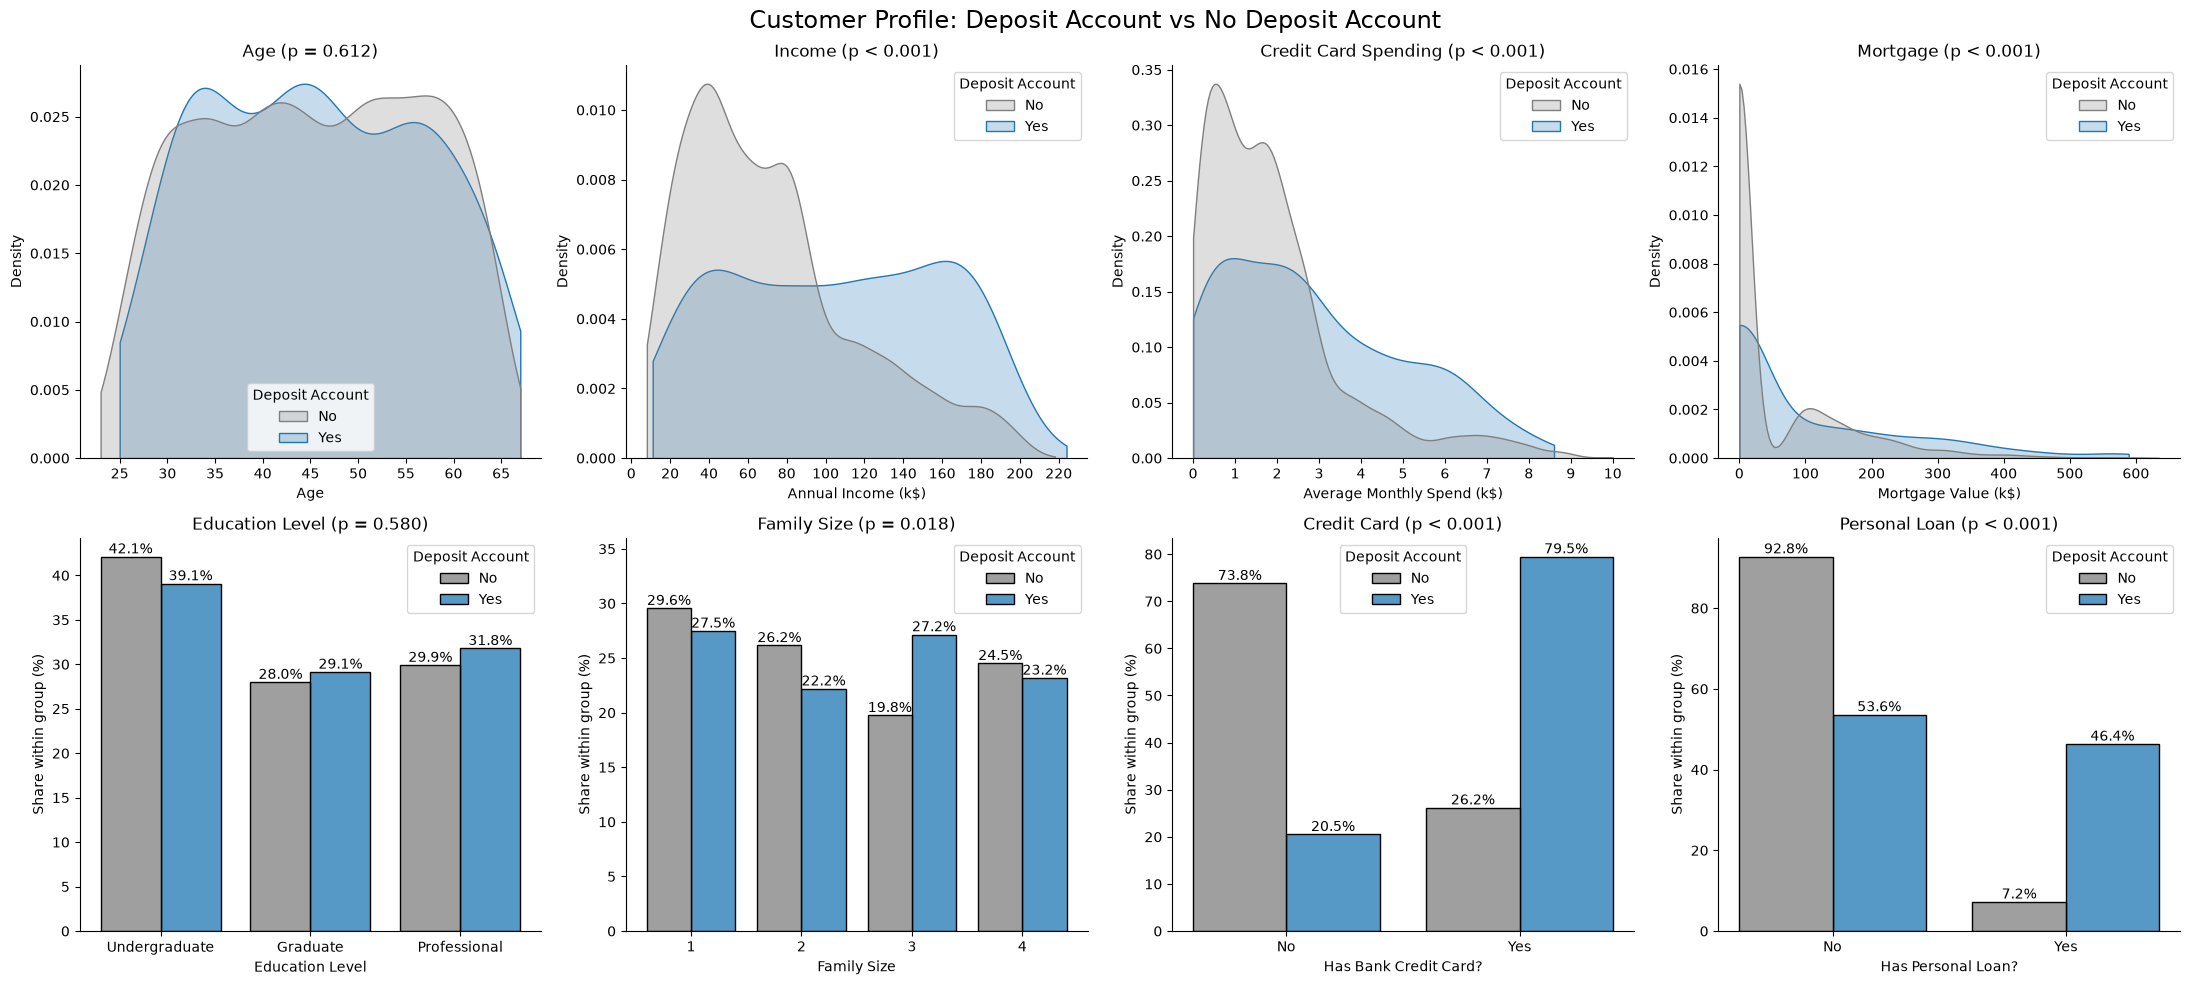

In [30]:
# Panel plot (2x4)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

# Row 1: Continuous variables
## Plot 1: Age
sns.kdeplot(
    data=data_plot,
    x="Age",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[0]
)
axes[0].set(
    title="Age (p = 0.612)",
    xlabel="Age",
    ylabel="Density",
    xticks=np.arange(25, 66, 5)
)

## Plot 2: Income
sns.kdeplot(
    data=data_plot,
    x="Income",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[1]
)
axes[1].set(
    title="Income (p < 0.001)",
    xlabel="Annual Income (k$)",
    ylabel="Density",
    xticks=np.arange(0, 240, 20)
)

## Plot 3: Average Credit Card Spending
sns.kdeplot(
    data=data_plot,
    x="CCAvg",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[2],
)
axes[2].set(
    title="Credit Card Spending (p < 0.001)",
    xlabel="Average Monthly Spend (k$)",
    ylabel="Density",
    xticks=np.arange(0, 11),
)

## Plot 4: House Mortgage Value
sns.kdeplot(
    data=data_plot,
    x="Mortgage",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    fill=True,
    common_norm=False, # scale density for each group for visibility
    cut=0, # cut density at maximum and minimum values
    ax=axes[3],
)
axes[3].set(
    title="Mortgage (p < 0.001)",
    xlabel="Mortgage Value (k$)",
    ylabel="Density",
    xticks=np.arange(0, 620, 100)
)

# Row 2: Categorical variables
## Plot 5: Education
sns.histplot(
    data=data_plot,
    x="Education",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[4],
)
label_bars(axes[4])
axes[4].set(
    title="Education Level (p = 0.580)",
    xlabel="Education Level",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

## Plot 6: Family Size
sns.histplot(
    data=data_plot,
    x="Family",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[5],
)
label_bars(axes[5])
axes[5].set(
    title="Family Size (p = 0.018)",
    xlabel="Family Size",
    ylabel="Share within group (%)",
    xticks=[1, 2, 3, 4],
    ylim=(0, 36)
)

## Plot 8: Credit Card
sns.histplot(
    data=data_plot,
    x="Credit Card",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[6]
)
label_bars(axes[6])
axes[6].set(
    title="Credit Card (p < 0.001)",
    xlabel="Has Bank Credit Card?", 
    ylabel="Share within group (%)"
)

## Plot 8: Personal Loan
sns.histplot(
    data=data_plot,
    x="Personal Loan",
    hue="Deposit Account",
    palette={"No": palette[7], "Yes": palette[0]}, # binary color choice
    multiple="dodge", # "no" and "yes" side by side
    stat="percent", # display percentages instead of counts
    common_norm=False, # compute percentages within each group
    discrete=True, # centering bars
    shrink=0.8, # reduce bars width
    ax=axes[7]
)
label_bars(axes[7])
axes[7].set(
    title="Personal Loan (p < 0.001)",
    xlabel="Has Personal Loan?", 
    ylabel="Share within group (%)"
)

plt.suptitle("Customer Profile: Deposit Account vs No Deposit Account", fontsize=17)
sns.despine()
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q5.pdf", bbox_inches="tight")
plt.show()

Compared to Securities Account holders who don't differ much, deposit account holders vary substantially compared to those who don't have this product. They have a much higher income, higher credit card spending, and higher mortgages. They are also more important users of the other banking products, including online banking and credit card. On the other hand, their education and age are similar to that of the rest of the customers

### Question 6: How many customers have one account only? How many have multiple accounts (i.e., both security and CD accounts)?

In [31]:
# Creating a label for each combination of Securities Account and Deposit Account
data_account = data.copy()
conditions = [
    (data_account["Securities Account"] == 0) & (data_account["Deposit Account"] == 0), # Without SA and without DA
    (data_account["Securities Account"] == 1) & (data_account["Deposit Account"] == 0), # With SA and without DA
    (data_account["Securities Account"] == 0) & (data_account["Deposit Account"] == 1), # Without SA and with DA
    (data_account["Securities Account"] == 1) & (data_account["Deposit Account"] == 1), # With SA and with DA
]
choices = ["Neither", "Securities only", "Deposit only", "Both accounts"] # Status
data_account["Account Status"] = np.select(conditions, choices, default="Unknown")

# Summary table
print(data_account["Account Status"].value_counts())
print(data_account["Account Status"].value_counts(normalize=True)*100)

Account Status
Neither            4323
Securities only     375
Deposit only        155
Both accounts       147
Name: count, dtype: int64
Account Status
Neither            86.46
Securities only     7.50
Deposit only        3.10
Both accounts       2.94
Name: proportion, dtype: float64


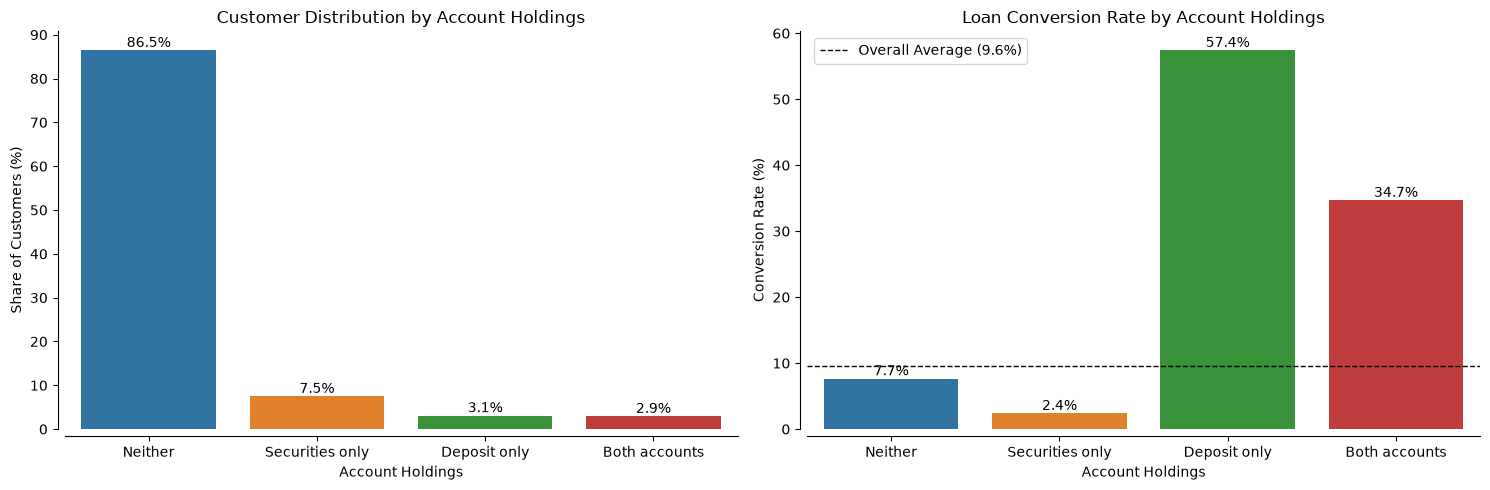

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left plot: Distribution of account holdings (%)
sns.countplot(
    data=data_account,
    x="Account Status",
    hue="Account Status",
    order=["Neither", "Securities only", "Deposit only", "Both accounts"], # lock the status order across plots
    hue_order=["Neither", "Securities only", "Deposit only", "Both accounts"], # lock the color order across plots
    stat="percent", # display percentages instead of counts
    legend=False, # hide legend labels (redundant with x-axis)
    ax=axes[0],
)
label_bars(axes[0]) # display percentage labels above bars
axes[0].set(
    title="Customer Distribution by Account Holdings",
    xlabel="Account Holdings",
    ylabel="Share of Customers (%)",
    yticks=np.arange(0, 91, 10)
)

# Right plot: Loan conversion rate
sns.barplot(
    data=data_account,
    x="Account Status",
    y=data_account["Personal Loan"] * 100,
    hue="Account Status",
    order=["Neither", "Securities only", "Deposit only", "Both accounts"], # lock the status order across plots
    hue_order=["Neither", "Securities only", "Deposit only", "Both accounts"], # lock the color order across plots
    errorbar=None, # remove CI bars
    legend=False, # hide legend labels (redundant with x-axis)
    ax=axes[1],
)
label_bars(axes[1]) # display percentage labels above bars
axes[1].axhline(
    data_account["Personal Loan"].mean() * 100,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Overall Average (9.6%)",
)
axes[1].legend() # Display average conversion rate legend
axes[1].set(
    title="Loan Conversion Rate by Account Holdings",
    xlabel="Account Holdings",
    ylabel="Conversion Rate (%)",
)

sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q6.pdf", bbox_inches="tight")
plt.show()

86.5% of customers hold neither account, 10.5% hold one account (7.5% for securities and 3.1% for deposit account) and only 2.9% hold both. Regarding the loan conversion rate, the deposit account drives most of the conversion : 57% of customer holding only a deposit account also contracted a personal loan, while only 2.4% for securities-only customers

### Question 7: What are the most important factors that lead to customers responding favorably to the marketing campaign?

In [33]:
# correlation of the target variable with every other features
data.corr(method="spearman")["Personal Loan"].sort_values(ascending=False).round(3)

Personal Loan         1.000
Income                0.431
Deposit Account       0.316
CCAvg                 0.314
Education             0.139
Mortgage              0.063
Family                0.062
Securities Account    0.022
Online Facilities     0.006
Credit Card           0.003
ZIP Code             -0.000
Experience           -0.008
Age                  -0.008
ID                   -0.025
Name: Personal Loan, dtype: float64

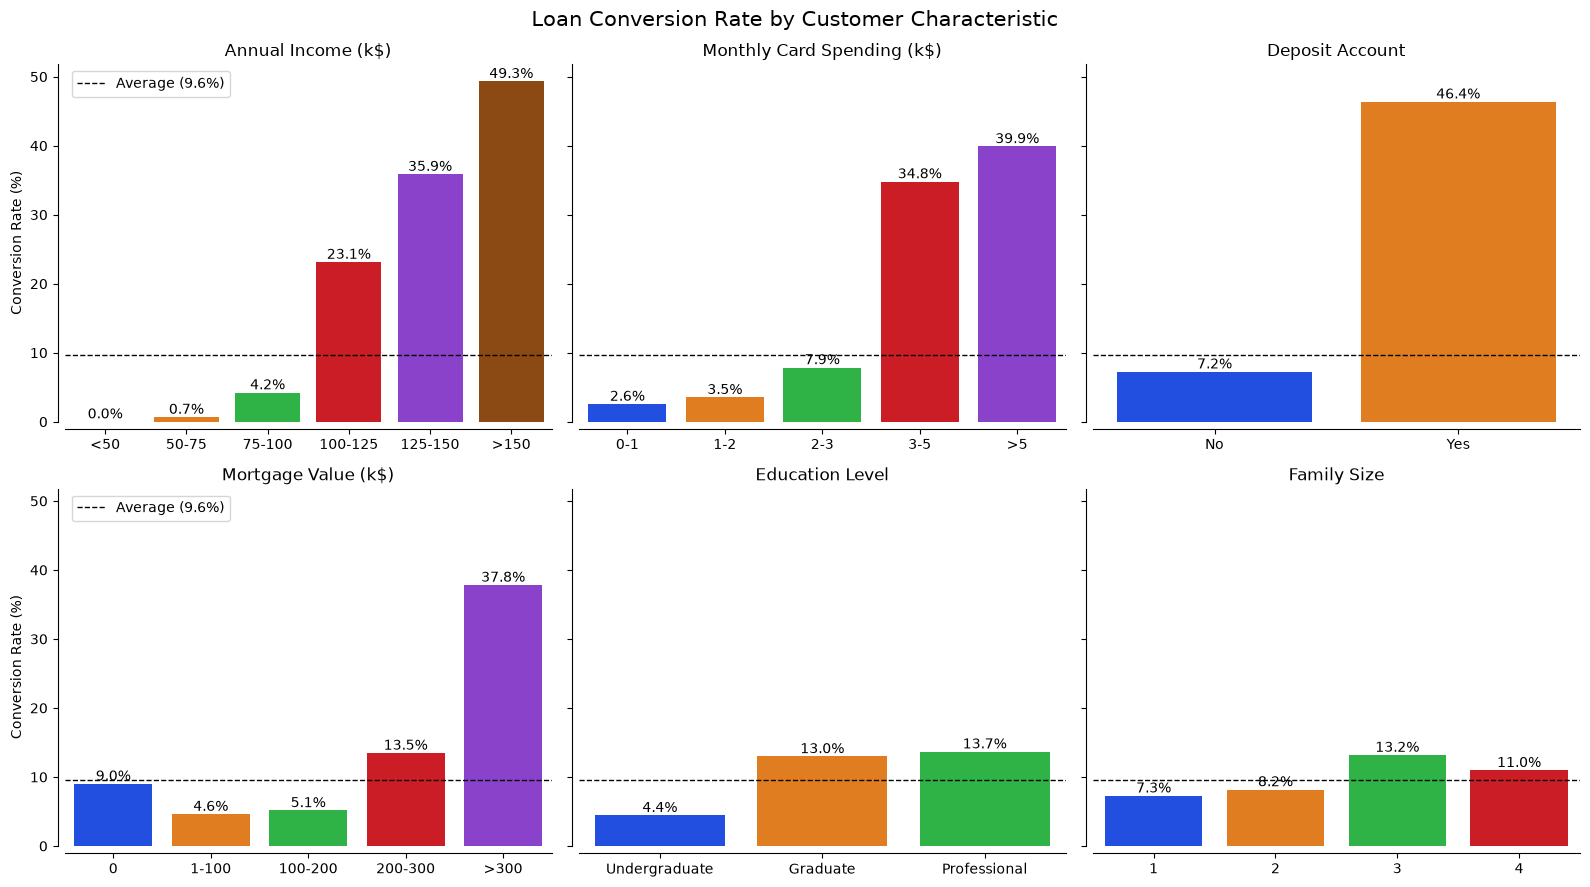

In [34]:
# Creating group categories for continuous variable
data_plot = data.copy()
data_plot["Age Band"] = pd.cut(
    data_plot["Age"],
    bins=[20, 29, 39, 49, 59, 70],
    labels=["23-29", "30-39", "40-49", "50-59", "60-67"],
)
data_plot["Income Band"] = pd.cut(
    data_plot["Income"],
    bins=[0, 50, 75, 100, 125, 150, 225],
    labels=["<50", "50-75", "75-100", "100-125", "125-150", ">150"],
)
data_plot["CCAvg Band"] = pd.cut(
    data_plot["CCAvg"],
    bins=[-0.01, 1, 2, 3, 5, 10], # start below 0 so exact 0 values are included in the first bin
    labels=["0-1", "1-2", "2-3", "3-5", ">5"],
)
data_plot["Mortgage Band"] = pd.cut(
    data_plot["Mortgage"],
    bins=[-1, 0, 100, 200, 300, 700],
    labels=["0", "1-100", "100-200", "200-300", ">300"],
)

average_rate = data["Personal Loan"].mean() * 100 # Defining the average rate of conversion (9,6%)

# Panel plot (2x3)
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True) # Same y-axis
axes = axes.flatten()

## Plot 1: Income
sns.barplot(
    data=data_plot,
    x="Income Band",
    y=data_plot["Personal Loan"] * 100, # mean loan conversion rate 
    hue="Income Band",
    palette="bright",
    dodge=False,
    legend=False,
    errorbar=None,
    ax=axes[0]
)
label_bars(axes[0]) # display percentage labels above bars
axes[0].axhline(
    average_rate, 
    color="black", 
    linestyle="--", 
    linewidth=1,
    label="Average (9.6%)"
)
axes[0].legend() 
axes[0].set(
    title="Annual Income (k$)",
    xlabel=None,
    ylabel="Conversion Rate (%)"
)

## Plot 2: Average Credit Card Spending
sns.barplot(
    data=data_plot,
    x="CCAvg Band",
    y=data_plot["Personal Loan"] * 100,  # mean loan conversion rate 
    hue="CCAvg Band",
    palette="bright",
    dodge=False, # centered bars
    errorbar=None, # hide CI bars
    ax=axes[1]
) 
label_bars(axes[1]) # display percentage labels above bars
axes[1].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1
)
axes[1].set(
    title="Monthly Card Spending (k$)",
    xlabel=None
)

## Plot 3: Deposit Account
sns.barplot(
    data=data_plot,
    x="Deposit Account",
    y=data_plot["Personal Loan"] * 100,  # mean loan conversion rate 
    hue="Deposit Account",
    palette="bright",
    dodge=False,   # centered bars
    legend=False, # hide legend labels redundant with x-axis
    errorbar=None, # hide CI bars
    ax=axes[2]
)
label_bars(axes[2]) # display percentage labels above bars
axes[2].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1
)
axes[2].set(
    title="Deposit Account", 
    xlabel=None,
    xticks=[0,1],
    xticklabels=["No", "Yes"]
)

## Plot 4: Mortgage
sns.barplot(
    data=data_plot,
    x="Mortgage Band",
    y=data_plot["Personal Loan"] * 100,  # mean loan conversion rate 
    hue="Mortgage Band",
    palette="bright",
    dodge=False, # centered bars
    legend=False, # hide legend labels redundant with x-axis
    errorbar=None, # hide CI bars
    ax=axes[3]
)
label_bars(axes[3]) # display percentage labels above bars
axes[3].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Average (9.6%)"
)
axes[3].legend(loc="upper left") # Display legend on the top left corner like above panel
axes[3].set(
    title="Mortgage Value (k$)",
    xlabel=None,
    ylabel="Conversion Rate (%)"
)

## Plot 5: Education 
sns.barplot(
    data=data_plot,
    x="Education",
    y=data_plot["Personal Loan"] * 100,  # mean loan conversion rate 
    hue="Education",
    palette="bright",
    dodge=False, # centered bars
    legend=False, # hide legend labels redundant with x-axis
    errorbar=None, # hide CI bars
    ax=axes[4]
)
label_bars(axes[4]) # display percentage labels above bars
axes[4].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1,
)
axes[4].set(
    title="Education Level",
    xlabel=None,
    xticks=[0, 1, 2],
    xticklabels=["Undergraduate", "Graduate", "Professional"],
)

## Plot 6: Family Size
sns.barplot(
    data=data_plot,
    x="Family",
    y=data_plot["Personal Loan"] * 100,  # mean loan conversion rate 
    hue="Family",
    palette="bright",
    dodge=False, # centered bars
    legend=False, # hide legend labels redundant with x-axis
    errorbar=None, # hide CI bars
    ax=axes[5]
)
label_bars(axes[5]) # display percentage labels above bars
axes[5].axhline(
    average_rate,
    color="black",
    linestyle="--",
    linewidth=1
)
axes[5].set(
    title="Family Size",
    xlabel=None
)

plt.suptitle("Loan Conversion Rate by Customer Characteristic", fontsize=15) # Overall title for the panel plot
sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q7a.pdf", bbox_inches="tight")
plt.show()

We now turn to a logistic regression to isolate effect of each variable everything else equal. 

In [35]:
# Selecting the relevant predictors (dropping ID, ZIP Code and Experience due to collinearity with Age)
X = data[["Age", "Income", "Family", "CCAvg", "Education", "Mortgage", "Securities Account",
          "Deposit Account", "Online Facilities", "Credit Card"]].copy()

# One-hot encoding of Education 
X = X.join(pd.get_dummies(X["Education"], prefix="Education")).drop("Education", axis = 1)
X = X.drop("Education_1", axis=1) # Undergraduate is dropped and serves as a reference category to avoid collinearity
X = X.rename(columns={"Education_2": "Graduate", "Education_3": "Professional"})
X["Graduate"] = X["Graduate"].astype(int) # Recoding True/False as binary (1/0)
X["Professional"] = X["Professional"].astype(int) # Recoding True/False as binary (1/0)

# Standardizing continuous variables (z-scores)
X["Age"] = (X["Age"] - X["Age"].mean()) / X["Age"].std()
X["Income"] = (X["Income"] - X["Income"].mean()) / X["Income"].std()
X["CCAvg"] = (X["CCAvg"] - X["CCAvg"].mean()) / X["CCAvg"].std()
X["Mortgage"] = (X["Mortgage"] - X["Mortgage"].mean()) / X["Mortgage"].std()

X.rename(columns={"CCAvg": "Credit Card Spending"}, inplace=True) # renaming for clarity

# Logistic regression model for the target variable 
X = sm.add_constant(X) # adding an intercept (baseline odds)
logit_model = sm.Logit(data["Personal Loan"], X).fit()

# Regression table
print(logit_model.summary()) # coefficients in log-odds

# Average marginal effects 
print(logit_model.get_margeff(dummy=True).summary_frame()) # discrete for binary variables, derivative for continuous

Optimization terminated successfully.
         Current function value: 0.117276
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:          Personal Loan   No. Observations:                 5000
Model:                          Logit   Df Residuals:                     4988
Method:                           MLE   Df Model:                           11
Date:                Fri, 27 Nov 2026   Pseudo R-squ.:                  0.6291
Time:                        23:41:47   Log-Likelihood:                -586.38
converged:                       True   LL-Null:                       -1581.0
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -8.2336      0.383    -21.505      0.000      -8.984      -7.483

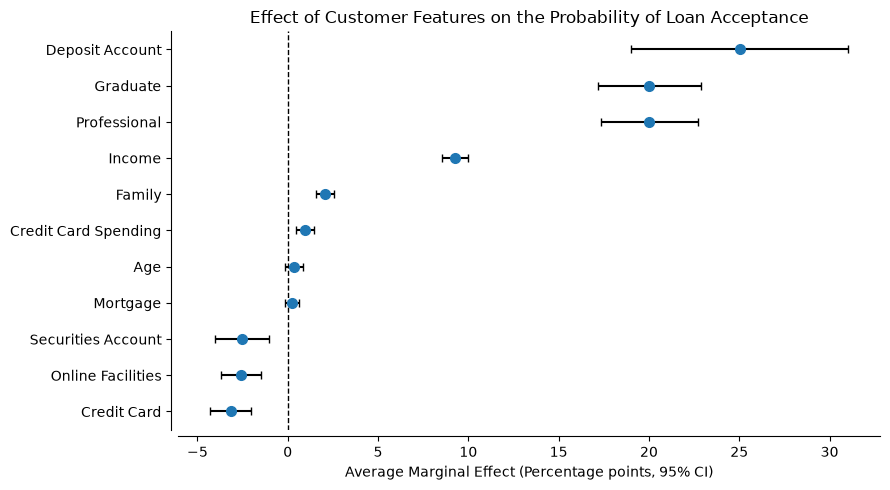

In [36]:
# Plotting the average marginal effect coefficients and CI
marginal_effects = logit_model.get_margeff(dummy=True).summary_frame()
marginal_effects["Coefficients"] = marginal_effects["dy/dx"]*100 # Coefficients converted to percentages points
marginal_effects["Low CI"] =  marginal_effects["Conf. Int. Low"]*100 # Low 95% confidence interval
marginal_effects["High CI"] =  marginal_effects["Cont. Int. Hi."]*100 # High 95% confidence interval
marginal_effects = marginal_effects.sort_values("Coefficients") # Ascending order 

# Plot
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(
    x=marginal_effects["Coefficients"],
    y=marginal_effects.index, # variables names on y-axis
    xerr=[marginal_effects["Coefficients"] - marginal_effects["Low CI"], 
          marginal_effects["High CI"] - marginal_effects["Coefficients"]],
    fmt="o", # point estimates as dots
    markersize=7, # increase dot size 
    ecolor="black", # color of the CI
    capsize=3 # size of the CI caps
)
ax.axvline(
    0, # null effect reference line
    color="black", 
    linestyle="--",
    linewidth=1
)
ax.set(
    title="Effect of Customer Features on the Probability of Loan Acceptance",
    xlabel="Average Marginal Effect (Percentage points, 95% CI)",
    ylabel=None
)

sns.despine(offset=5)
plt.tight_layout()

# Saving the figure for the report
plt.savefig("figures/q7b.pdf", bbox_inches="tight")
plt.show()

### Question 8: Build a simple machine learning classification model that predicts, based on a customer's features, if they will respond to the marketing campaign or not.

We decide to opt for a standard decision tree classifier to predict loan acceptance (non-linear feature interactions compared to logit). Due to the target variable imbalance (only 9.6% of conversion rate), need to use alternative metrics other than accuracy to assess model performances (recall, precision)

##### Decision Tree (Standard specification)

In [37]:
# Selection of explanatory features and target variable 
X = data[["Age", "Income", "Family", "CCAvg", "Education", "Mortgage",
          "Securities Account", "Deposit Account", "Online Facilities", "Credit Card"]]
y = data["Personal Loan"]

# Decision Tree
## We use grid search and trainsplits: most of the code is re-used from our Machine Learning labs with Pr Rossi

## Data split into train/validation (80%) and test set (20%), stratified to account for class imbalances
X_tv, X_test, Y_tv, Y_test = model_selection.train_test_split(
    X, y, test_size = 0.2, stratify = y, random_state=0
)

## 4 stratified random splits (75% train, 25% validation) for cross-validation
v_split = StratifiedShuffleSplit(n_splits=4, train_size=0.75, random_state=0) 

## Hyperparameter grid search controlling for tree complexity
algorithm_params = {
    'min_samples_split': [2, 10, 20, 40, 60, 80, 100, 150, 200, 300], # min samples required to split a node
    'max_depth': list(range(2, 11, 1)), # max number of consecutive splits from root to leaf
    'min_impurity_decrease': np.linspace(0, 0.005, 11) # min Gini impurity reduction required to split
}

# Search across all parameter combinations and fit the best tree on the full train/validation set
grid_search = GridSearchCV(DecisionTreeClassifier(random_state = 0),algorithm_params, cv = v_split, scoring="f1") # using F1 score instead of accuracy
grid_search = grid_search.fit(X_tv, Y_tv)

In [38]:
# Inspecting top 10 hyperparameters combinations by validation accuracy
results = pd.DataFrame(grid_search.cv_results_)
results[['param_min_samples_split', 'param_max_depth',
         'param_min_impurity_decrease','mean_test_score']].sort_values('mean_test_score', ascending= False).head(10)

,param_min_samples_split,param_max_depth,param_min_impurity_decrease,mean_test_score
683,40,8,0.0010,0.934215
553,40,7,0.0000,0.934215
893,40,10,0.0005,0.934215
773,40,9,0.0000,0.934215
903,40,10,0.0010,0.934215
663,40,8,0.0000,0.934215
793,40,9,0.0010,0.934215
783,40,9,0.0005,0.934215
453,40,6,0.0005,0.934215
673,40,8,0.0005,0.934215


In [39]:
print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': 6, 'min_impurity_decrease': np.float64(0.0), 'min_samples_split': 40}
0.9342149764470429


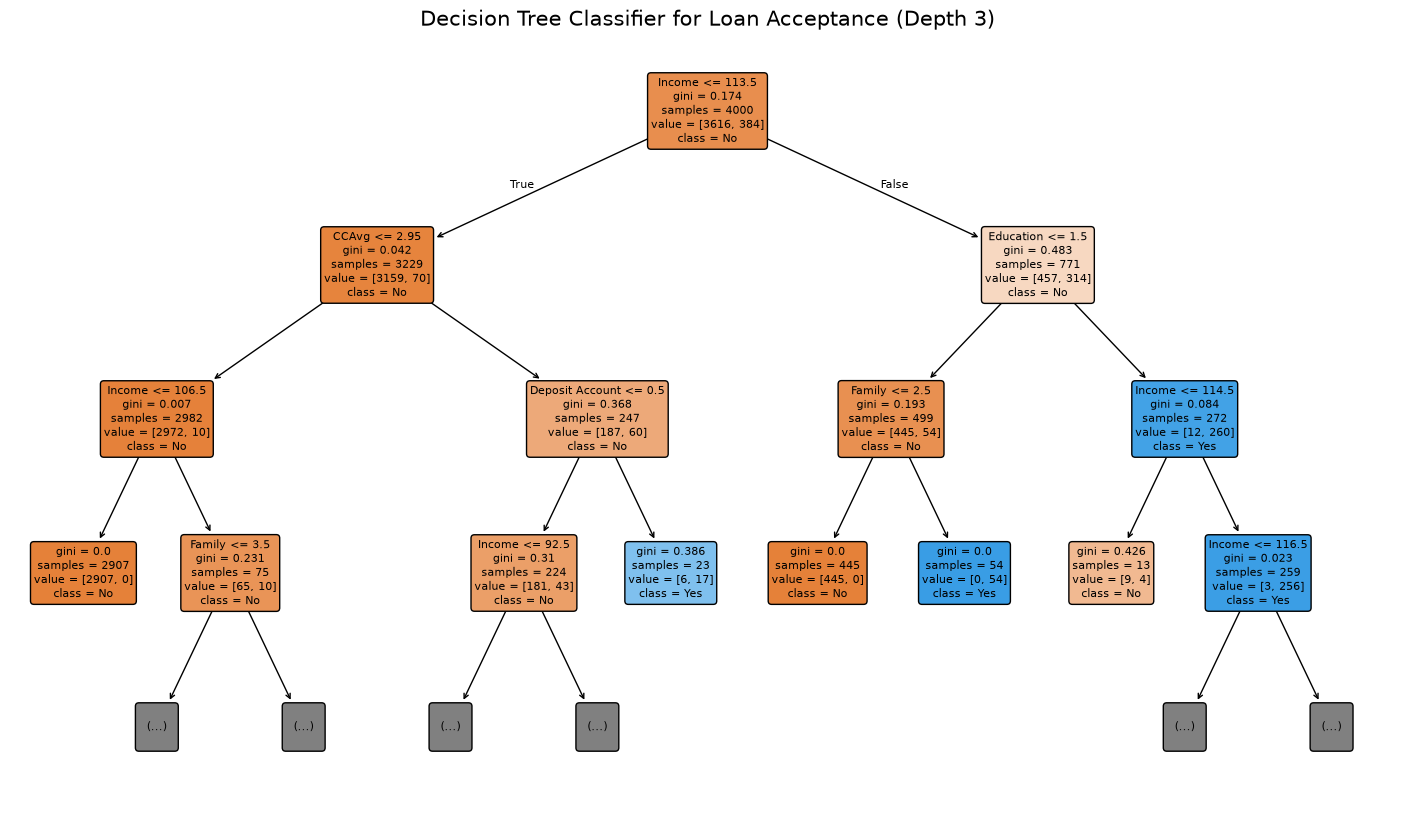

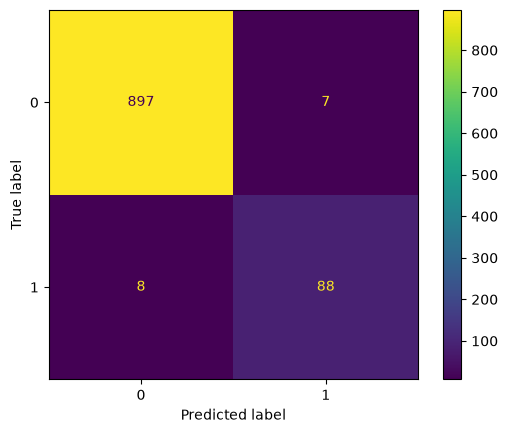

In [40]:
# Plotting the best decision tree
best = grid_search.best_estimator_

fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    best, 
    feature_names=X.columns,
    class_names=["No", "Yes"], # display predicted class names in nodes
    filled=True, # color nodes based on majority class
    rounded=True, # rounded corners of node boxes
    max_depth=3, # maximum tree depth displayed
    ax=ax
)
ax.set_title("Decision Tree Classifier for Loan Acceptance (Depth 3)", fontsize=15)

# Saving the figure for the report
plt.savefig("figures/q8a.pdf", bbox_inches="tight")
plt.show()

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(best,X_test, Y_test)
plt.savefig("figures/q8b.pdf", bbox_inches="tight") # write manually the confusion matrix in the report instead (Latex)

In [41]:
# Manually computing the recall (TP/TP+FN)
recall = 88/(88+8)
print(recall)
print("precision:", 88/(88+7))

0.9166666666666666
precision: 0.9263157894736842


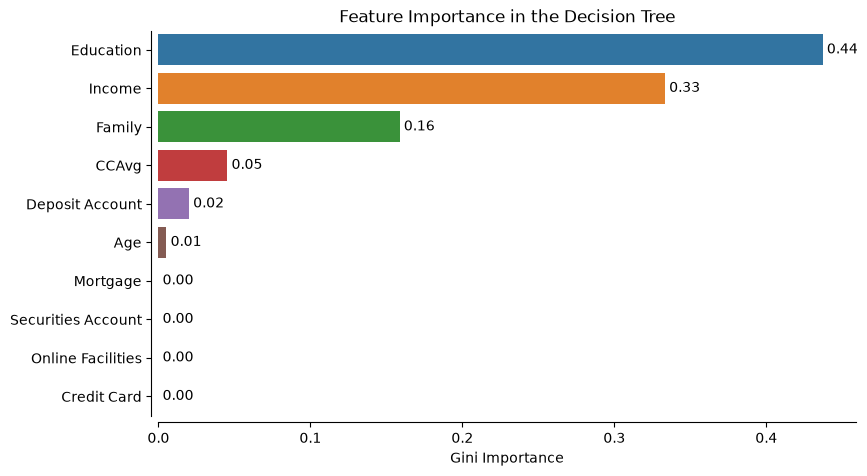

In [42]:
# Compute and sort feature importance
importances = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False) # Descending order

# Plot
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    x=importances.values, # gini importance
    y=importances.index, # variable names
    hue=importances.index,
    ax=ax
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3) # Adding value labels at the top of the bars with small gap for clarity

ax.set(
    title="Feature Importance in the Decision Tree",
    xlabel="Gini Importance",
    ylabel=None
)

sns.despine(offset=5)

# Saving the figure for the report
plt.savefig("figures/q8c.pdf", bbox_inches="tight")
plt.show()

##### Decision Tree (Weighted Loss Function specification)

We would like to penalise the false negative harder than false positive, since missed customers cost us more than reached customers who are not interested in our product. We can do this using `class_weight` parameter in `DecisionTreeClassifier`.

In [43]:
# Selection of explanatory features and target variable (identical to baseline tree for fair comparison)
X = data[["Age", "Income", "Family", "CCAvg", "Education", "Mortgage",
          "Securities Account", "Deposit Account", "Online Facilities", "Credit Card"]]
y = data["Personal Loan"]

# Penalized Decision Tree (cost-sensitive learning)
## Data split into train/validation (80%) and test set (20%), stratified to account for class imbalances
X_tv, X_test, Y_tv, Y_test = model_selection.train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=0
)

## 4 stratified random validation splits (75% train, 25% validation) for cross-validation
v_split = StratifiedShuffleSplit(n_splits=4, train_size=0.75, random_state=0)

## Hyperparameter grid search controlling for tree complexity
algorithm_params = {
    "min_samples_split": [2, 10, 20, 40, 60, 80, 100, 150, 200, 300],  # min samples required to split a node
    "max_depth": list(range(2, 11, 1)),  # max number of consecutive splits from root to leaf
    "min_impurity_decrease": np.linspace(0, 0.005, 11),  # min weighted Gini impurity reduction required to split

}
tree_pen = DecisionTreeClassifier(random_state=0, class_weight={0:1 , 1:4})

# Search across all parameter combinations and fit the best penalized tree on the full train/validation set
grid_search_pen = GridSearchCV(tree_pen, algorithm_params, cv=v_split, scoring="f1", n_jobs=-1)
grid_search_pen = grid_search_pen.fit(X_tv, Y_tv)

In [44]:
print(grid_search_pen.best_params_)

{'max_depth': 9, 'min_impurity_decrease': np.float64(0.0), 'min_samples_split': 2}


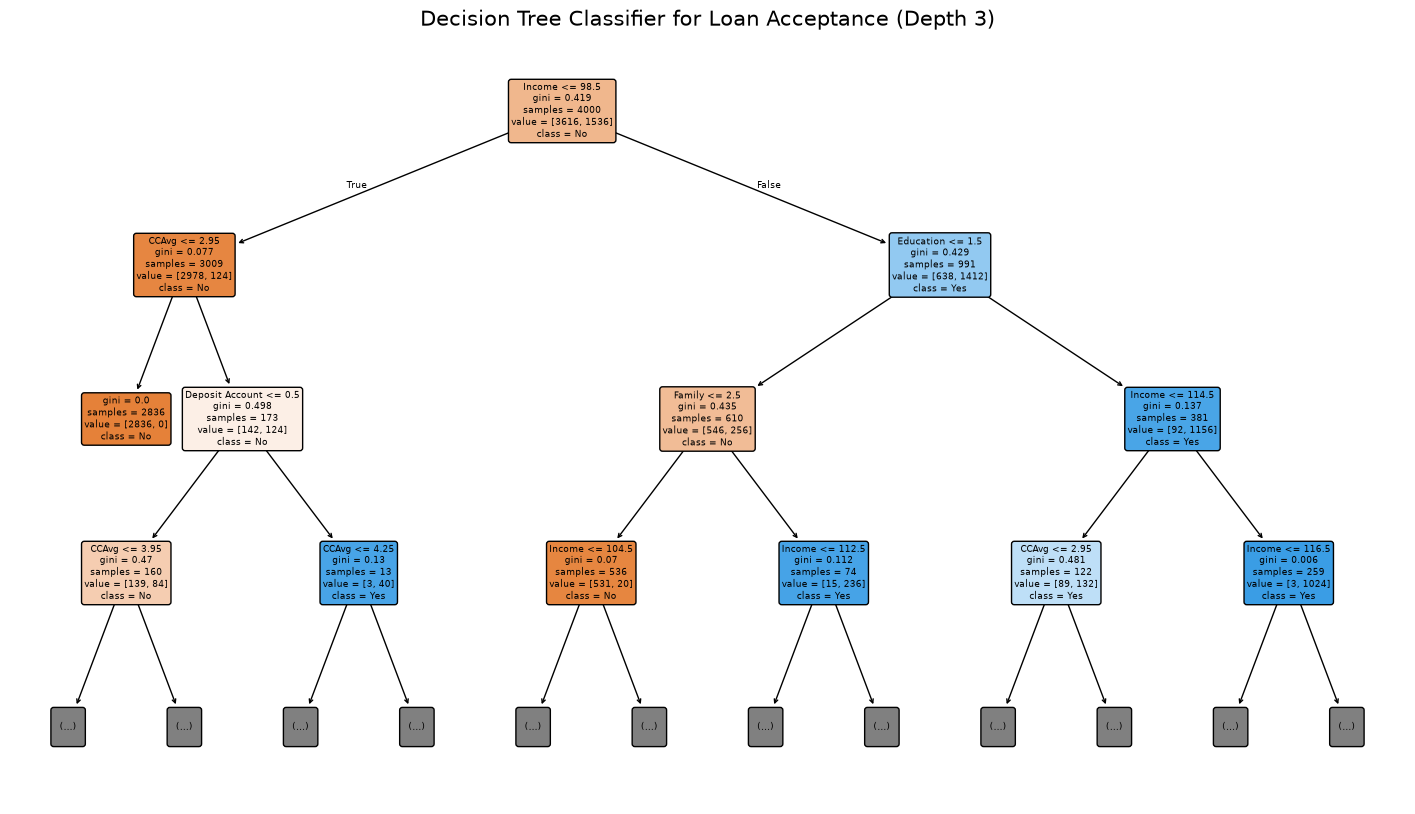

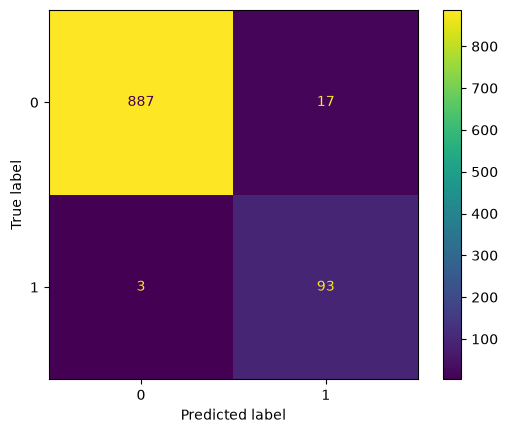

In [45]:
# Plotting the best decision tree for penalised
best_pen = grid_search_pen.best_estimator_

fig, ax = plt.subplots(figsize=(18, 10))
plot_tree(
    best_pen, 
    feature_names=X.columns,
    class_names=["No", "Yes"], # display predicted class names in nodes
    filled=True, # color nodes based on majority class
    rounded=True, # rounded corners of node boxes
    max_depth=3, # maximum tree depth displayed
    ax=ax
)
ax.set_title("Decision Tree Classifier for Loan Acceptance (Depth 3)", fontsize=15)

# Saving the figure for the report
plt.savefig("figures/q8d.pdf", bbox_inches="tight")
plt.show()
# COnfusion matrix
ConfusionMatrixDisplay.from_estimator(best_pen,X_test, Y_test)
plt.savefig("figures/q8e.pdf", bbox_inches="tight")

In [46]:
# Accuracy and recall of our second tree ((TP + TN)/n)
acc = (887+93)/1000
print(acc)

recall_pen = 93/(3+93)
print(recall_pen)

print("precision:", 93/(93+17))

0.98
0.96875
precision: 0.8454545454545455


In [47]:
### Grid search with weight as a parameter (not run: ~40,000 fits, no improvement over the fixed weight)

# # Selection of explanatory features and target variable (identical to baseline tree for fair comparison)
# X = data[["Age", "Income", "Family", "CCAvg", "Education", "Mortgage",
#           "Securities Account", "Deposit Account", "Online Facilities", "Credit Card"]]
# y = data["Personal Loan"]

# # Penalized Decision Tree (cost-sensitive learning)
# ## Data split into train/validation (80%) and test set (20%), stratified to account for class imbalances
# X_tv, X_test, Y_tv, Y_test = model_selection.train_test_split(
#     X, y, test_size=0.2, stratify=y, random_state=0
# )

# ## 4 stratified random validation splits (75% train, 25% validation) for cross-validation
# v_split = StratifiedShuffleSplit(n_splits=4, train_size=0.75, random_state=0)

# ## Hyperparameter grid search controlling for tree complexity
# algorithm_params = {
#     "min_samples_split": [2, 10, 20, 40, 60, 80, 100, 150, 200, 300],  # min samples required to split a node
#     "max_depth": list(range(2, 11, 1)),  # max number of consecutive splits from root to leaf
#     "min_impurity_decrease": np.linspace(0, 0.005, 11),  # min weighted Gini impurity reduction required to split
#     "class_weight": [{0: 1, 1: i} for i in range(1, 11)],  # class weight tuned as a hyperparameter
# }
# tree_pen = DecisionTreeClassifier(random_state=0)

# # Search across all parameter combinations and fit the best penalized tree on the full train/validation set
# grid_search_weight = GridSearchCV(tree_pen, algorithm_params, cv=v_split, scoring="f1", n_jobs=-1)
# grid_search_weight = grid_search_weight.fit(X_tv, Y_tv)